# tempdisagg by example

This notebook walks through the library with real data: annual sales of the Swiss chemical and
pharmaceutical industry, and its quarterly exports and imports. The same data come with the R
package `tempdisagg`, which is what we use to check that both libraries give the same numbers.

The question is always the same: we know a series once a year and want a sensible quarterly path
that adds up to the annual figures. Each section shows one tool and what it is good for.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tempdisagg as td
from tempdisagg.datasets import load_swisspharma

plt.rcParams.update({"figure.figsize": (9, 3.4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e7eb"})
td.__version__

'0.6.2'

## The data

`sales` is an annual index (1975–2010). `trade` has quarterly exports and imports in millions of
francs (1972Q1–2011Q2), so the indicators start three years earlier and end half a year later than
the target. Those extra quarters will be retropolated and extrapolated.

In [2]:
sales, trade = load_swisspharma()
print(sales.tail(3))
trade.tail(3)

2008    1000.371339
2009    1045.639301
2010     988.309676
Freq: Y-DEC, Name: sales, dtype: float64


,exports,imports
2010Q4,18026.468690,9720.359503
2011Q1,19687.520999,9521.849559
2011Q2,18913.066084,9676.744206


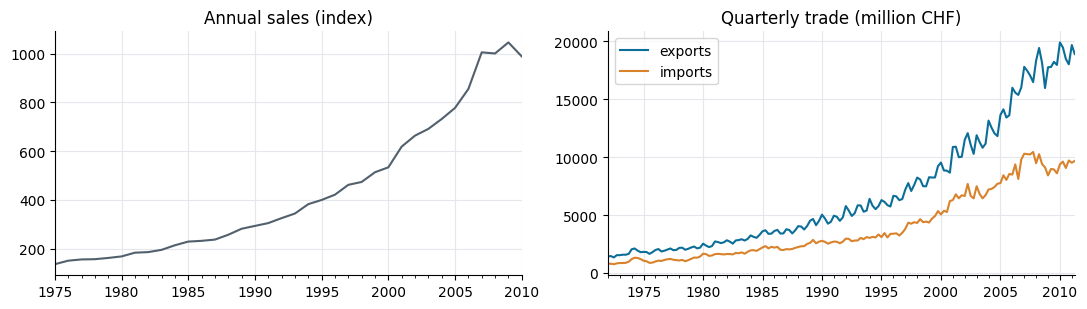

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
sales.plot(ax=left, title="Annual sales (index)", color="#52606d")
trade.plot(ax=right, title="Quarterly trade (million CHF)", color=["#0b6e99", "#d9822b"])
plt.tight_layout()

## A first disaggregation: Chow-Lin

Chow-Lin regresses the annual target on the annual sum of the indicator, builds a quarterly
series from the fitted values, and then spreads the annual residuals over the quarters assuming
they follow an AR(1). The result always adds up to the annual data. `chow-lin-maxlog` estimates
the AR parameter by maximum likelihood; it is the default, as in R.

In [4]:
model = td.TemporalDisaggregator("chow-lin-maxlog")
result = model.fit(sales, trade[["exports"]])
print(result.summary())

'chow-lin-maxlog' disaggregation with 'sum' conversion
36 low-freq. obs. converted to 158 high-freq. obs.

Residuals (low frequency):
    Min      1Q  Median     3Q    Max
-77.892 -7.7108 -4.6276 9.6465 36.448

Coefficients:
             Estimate  Std. Error  t value    Pr(>|t|)     
(Intercept)   12.4089     1.49303  8.31119 1.06081e-09  ***
exports     0.0133918 0.000167167  80.1106 2.53953e-40  ***
---
Signif. codes: 0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual std. error (GLS): 10.4417 on 34 degrees of freedom
Multiple R-squared: 0.9947   Adjusted R-squared: 0.9946
Log-likelihood: -159.4555   AIC: 4.7456   BIC: 4.8335   (likelihood-based AIC: 326.9109)
Lag-1 autocorrelation of whitened residuals: -0.0804
AR1-Parameter: 0.000000 (estimated by maxlog, truncated (unconstrained -0.306953))
Max. aggregation error: 2.274e-13


The coefficient on exports is very precise and the fit is high, but the estimated rho was
negative and got truncated to zero. That is R's default behaviour too (`truncated_rho=0`): a
negative rho tends to produce saw-tooth quarters. With rho at zero the residuals are spread evenly.

`result.values` is the quarterly series. For regression methods we also get a standard error per
quarter, so we can draw an interval around the estimate.

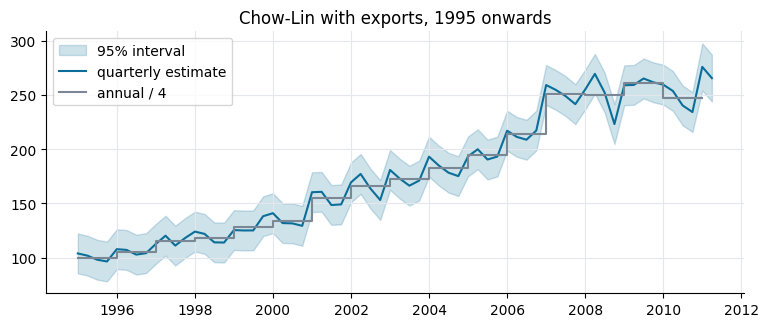

In [5]:
band = result.prediction_interval(0.95).loc["1995":]
x = band.index.to_timestamp()
plt.fill_between(x, band["lower"], band["upper"], color="#0b6e99", alpha=0.2, label="95% interval")
plt.plot(x, band["estimate"], color="#0b6e99", label="quarterly estimate")
plt.step(x, (sales / 4).reindex(band.index.asfreq("Y")).to_numpy(), where="post",
         color="#7b8794", label="annual / 4")
plt.legend(loc="upper left"); plt.title("Chow-Lin with exports, 1995 onwards");

The interval treats rho as known, so it is a bit narrow, but it is useful to see where the
estimate is fragile, for example in the extrapolated quarters of 2011.

## Several indicators, with or without a constant

Every regression method accepts any number of indicators. All of them include an intercept by
default (like `y ~ x` in R); `include_intercept=False` gives `y ~ 0 + x`.

In [6]:
two = td.TemporalDisaggregator().fit(sales, trade)
no_constant = td.TemporalDisaggregator(include_intercept=False).fit(sales, trade[["exports"]])
pd.concat({"exports + imports": two.regression.table(),
           "exports, no intercept": no_constant.regression.table()})

Estimate  Std. Error  ...      Pr(>|t|)     
exports + imports     (Intercept)  11.685855    1.493077  ...  5.079349e-09  ***
                      exports       0.011258    0.001158  ...  3.255720e-11  ***
                      imports       0.003934    0.002113  ...  7.158878e-02    .
exports, no intercept exports       0.014160    0.000343  ...  2.723516e-31  ***

[4 rows x 5 columns]

Imports add little here (p around 0.07). Every setting of a method can be listed with
`describe()`, which also shows the equivalent R argument.

In [7]:
td.TemporalDisaggregator("fernandez", include_intercept=False).describe()

,value,description,R argument
parameter,,,
include_intercept,False,add a constant regressor,formula: y ~ x vs y ~ 0 + x


## Other residual models

Note that `truncated_rho=-1` lets rho be negative; Fernández has no rho to estimate, so it does not
accept that setting (asking for it raises an error that lists the valid ones).

The regression methods differ only in what they assume about the quarterly residuals:

* **Chow-Lin**: stationary AR(1).
* **Fernández**: a random walk. Good when the gap between target and indicator drifts.
* **Litterman**: a random walk whose changes follow an AR(1).
* **Dynamic Chow-Lin** (experimental, as in R): the target depends on its own lag.

To compare them, use the likelihood-based AIC (`aic_loglik`). The `aic` column follows R's
definition, which depends on how each model scales its covariance matrix, so it only makes sense
within one family.

In [8]:
models = {
    "chow-lin-maxlog": td.TemporalDisaggregator("chow-lin-maxlog", truncated_rho=-1),
    "fernandez": td.TemporalDisaggregator("fernandez"),  # rho is 0 by definition
    "litterman-maxlog": td.TemporalDisaggregator("litterman-maxlog", truncated_rho=-1),
    "dynamic-maxlog": td.TemporalDisaggregator("dynamic-maxlog", truncated_rho=-1),
}
rows = {}
for name, model in models.items():
    fit = model.fit(sales, trade[["exports"]])
    rows[name] = {"rho": fit.rho.value, "logL": fit.regression.log_likelihood,
                  "aic_loglik": fit.regression.aic_loglik, "aic (R)": fit.regression.aic}
pd.DataFrame(rows).T.round(3)

,rho,logL,aic_loglik,aic (R)
chow-lin-maxlog,-0.307,-159.344,326.689,5.125
fernandez,0.000,-173.592,353.183,3.141
litterman-maxlog,-0.999,-172.124,352.247,4.334
dynamic-maxlog,-0.999,-158.514,327.027,5.443


The warnings are worth reading. Litterman and the dynamic model push rho to the lower bound
of the search interval, and some likelihoods have competing local optima (`result.rho.profile`
shows the whole curve). With unconstrained rho none of these models looks comfortable with this
data; the default truncation at zero exists for this reason.

Also note how the two AICs disagree. By `aic_loglik`, Chow-Lin and the dynamic model fit best;
by R's `aic`, Fernández would come first, but only because its covariance matrix is scaled
differently.

The dynamic model has a further problem when it has to go back in time: in 1972–1974 its estimate
explodes. R gives the same numbers, which is precisely why both libraries label it experimental.

In [9]:
dynamic = td.TemporalDisaggregator("dynamic-fixed", fixed_rho=0.5).fit(sales, trade[["exports"]])
dynamic.values.loc[:"1976"].round(1).to_frame().T

,1972Q1,1972Q2,1972Q3,1972Q4,1973Q1,1973Q2,1973Q3,1973Q4,1974Q1,1974Q2,1974Q3,1974Q4,1975Q1,1975Q2,1975Q3,1975Q4,1976Q1,1976Q2,1976Q3,1976Q4
estimate,-26628.3,-13297.7,-6633.2,-3299.7,-1632.9,-799.2,-382.4,-173.5,-66.3,-12.3,13.4,25.4,31.6,34.5,34.8,35.8,37.2,38.4,37.7,37.8


## Denton: adjusting an indicator to the totals

Denton does not estimate a regression. It takes the indicator as it is and moves it as little as
possible so that it matches the annual figures. With the proportional criterion it keeps the
quarter-to-quarter growth rates of the indicator; with the additive one it keeps the differences.
`h` is the order of the differences being preserved.

The original Denton (1971) assumes that the series starts exactly at the indicator. Here the
indicator is in millions of francs and sales are an index around 30, so the start of the series
is dragged towards the indicator's level. Denton-Cholette drops that assumption.

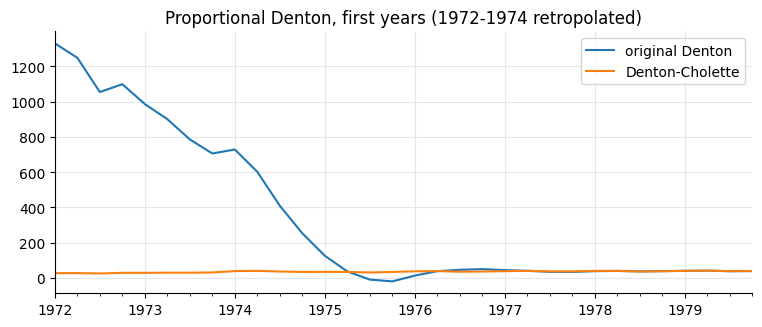

In [10]:
cholette = td.TemporalDisaggregator("denton-cholette").fit(sales, trade[["exports"]]).values
original = td.TemporalDisaggregator("denton").fit(sales, trade[["exports"]]).values
original.loc[:"1979"].plot(label="original Denton")
cholette.loc[:"1979"].plot(label="Denton-Cholette")
plt.legend(); plt.title("Proportional Denton, first years (1972-1974 retropolated)");

For the same reason the additive criterion is a poor choice here: it would transfer the
quarterly swings of exports, measured in millions, to an index measured in tens, and even produce
negative sales. Additive Denton is meant for an indicator in the same units as the target.

### No indicator at all

Sometimes there is nothing to follow. Then the choice is between splitting each year evenly
(`uniform`) or drawing the smoothest path that still matches the totals (`denton-cholette`
without an indicator). No indicator column is needed; just say the output frequency.

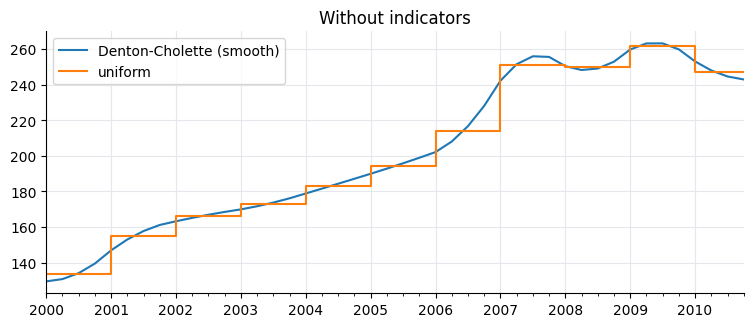

In [11]:
smooth = td.disaggregate(sales, method="denton-cholette", high_freq="Q")
even = td.disaggregate(sales, method="uniform", high_freq="Q")
smooth.loc["2000":].plot(label="Denton-Cholette (smooth)")
even.loc["2000":].plot(label="uniform", drawstyle="steps-post")
plt.legend(); plt.title("Without indicators");

## How good is the result? A test with known quarters

For sales we never see the true quarters, so we cannot measure errors directly. Exports are
different: we have them quarterly. If we add them up to years, pretend we only know the annual
figures, and disaggregate, we can compare against the real quarters.

Below we disaggregate exports with imports as the indicator.

In [12]:
in_sample = trade.index.year <= 2010
exports_q = trade.loc[in_sample, "exports"]
imports_q = trade.loc[in_sample, ["imports"]]
exports_a = td.temporal_aggregate(exports_q, "Y")

def rmse(estimate):
    return float(np.sqrt(np.mean((estimate - exports_q) ** 2)))

errors = {}
for method in ["chow-lin-maxlog", "fernandez", "litterman-maxlog", "denton-cholette"]:
    errors[method] = rmse(td.disaggregate(exports_a, imports_q, method=method))
errors["uniform (no indicator)"] = rmse(td.disaggregate(exports_a, method="uniform", high_freq="Q"))
pd.Series(errors, name="RMSE (million CHF)").round(1).sort_values()

uniform (no indicator)    348.5
chow-lin-maxlog           413.3
fernandez                 413.4
litterman-maxlog          416.1
denton-cholette           443.8
Name: RMSE (million CHF), dtype: float64

Splitting each year evenly beats every method that uses imports. The reason is simple:
quarterly imports and exports move together only loosely (their quarterly growth rates have a
correlation of about 0.5), so following imports adds noise. An indicator is only worth using if
its short-term movements resemble those of the target, and this is easy to forget when the annual
correlation is very high.

## Choosing a model with a backtest

When the true quarters are unknown, the only out-of-sample check we have is the next annual
figure. `backtest` hides each of the last years in turn, fits with the earlier years, extrapolates
the hidden year from the indicators and compares the sum with the real total.

In [13]:
candidates = {
    "Chow-Lin, exports": td.Candidate(td.TemporalDisaggregator(), trade[["exports"]]),
    "Chow-Lin, exports + imports": td.Candidate(td.TemporalDisaggregator(), trade),
    "Fernandez, exports": td.Candidate(td.TemporalDisaggregator("fernandez"), trade[["exports"]]),
    "Denton-Cholette, exports": td.Candidate(td.TemporalDisaggregator("denton-cholette"),
                                             trade[["exports"]]),
    "Denton-Cholette, no indicator": td.Candidate(td.TemporalDisaggregator("denton-cholette")),
}
backtest = td.backtest(sales, candidates, holdout=6, high_freq="Q")
backtest.summary().round(2)

,n_origins,bias,MAE,RMSE,MAPE_%
"Chow-Lin, exports",6,13.78,52.57,59.12,5.48
"Chow-Lin, exports + imports",6,0.50,56.51,65.64,5.87
"Fernandez, exports",6,11.15,61.23,72.19,6.21
"Denton-Cholette, no indicator",6,-31.06,66.75,74.37,7.01
"Denton-Cholette, exports",6,19.11,66.87,75.95,6.86


Chow-Lin with exports alone extrapolates best, and adding imports makes it slightly worse,
which agrees with the coefficient table above. Six years is a small sample, so this is evidence,
not proof. The backtest also says nothing about the shape inside each year.

## Using extra information: known quarters

Sometimes a few quarterly values are known from another source. They can be passed as exact
constraints and every method will honour them. Here we pretend that the second quarter of every
fourth year is known.

In [14]:
known = exports_q[(exports_q.index.quarter == 2) & (exports_q.index.year % 4 == 0)]
constraints = td.known_values(known)

base = td.TemporalDisaggregator().fit(exports_a, imports_q)
informed = td.TemporalDisaggregator().fit(exports_a, imports_q, constraints=constraints)
others = ~exports_q.index.isin(known.index)
print("known quarters reproduced:", np.allclose(informed.values[known.index], known))
print("rho without / with constraints:", round(base.rho.value, 3), round(informed.rho.value, 3))
print("RMSE on the other quarters:", round(rmse(base.values[others]), 1),
      round(rmse(informed.values[others]), 1))

known quarters reproduced: True
rho without / with constraints: 0.998 0.91
RMSE on the other quarters: 419.9 440.3


The known quarters are reproduced exactly, but the rest of the series got slightly worse.
The constraints are also data for the estimation, and here they pulled rho from 0.998 down to 0.91
and changed the coefficients. With a weak indicator that change did not pay off. Fixing rho, or
using a method without rho such as Fernández, keeps the benefit local:

In [15]:
fixed = td.TemporalDisaggregator("chow-lin-fixed", fixed_rho=round(base.rho.value, 3))
print("Chow-Lin, rho fixed:", round(rmse(fixed.fit(exports_a, imports_q,
                                                   constraints=constraints).values[others]), 1))
fz = td.TemporalDisaggregator("fernandez")
print("Fernandez without / with:", round(rmse(fz.fit(exports_a, imports_q).values[others]), 1),
      round(rmse(fz.fit(exports_a, imports_q, constraints=constraints).values[others]), 1))

Chow-Lin, rho fixed: 415.0
Fernandez without / with: 419.7 414.4


Totals at an intermediate frequency (a few known quarters when the output is monthly, for
example) work the same way with `td.aggregate_constraints`. If the constraints contradict each
other, the library stops and says which values clash.

## Series that must add up: reconciliation

Suppose we have annual exports and imports, and total trade is known every quarter. Each series
can be disaggregated on its own, but then exports + imports will not match the quarterly total.
`CrossSectionalReconciler` adjusts both series so that the sum matches every quarter while each
still matches its own annual figures.

In [16]:
imports_qs = trade.loc[in_sample, "imports"]
imports_a = td.temporal_aggregate(imports_qs, "Y")
total_q = exports_q + imports_qs

separate = {
    "exports": td.TemporalDisaggregator("denton-cholette").fit(exports_a, high_freq="Q"),
    "imports": td.TemporalDisaggregator("denton-cholette").fit(imports_a, high_freq="Q"),
}
system = td.CrossSectionalReconciler().reconcile_results(separate, total_q)

truth = {"exports": exports_q, "imports": imports_qs}
pd.DataFrame({
    name: {"RMSE separate": float(np.sqrt(np.mean((separate[name].values - truth[name]) ** 2))),
           "RMSE reconciled": float(np.sqrt(np.mean((system.values[name] - truth[name]) ** 2)))}
    for name in truth}).round(1)

,exports,imports
RMSE separate,452.8,197.5
RMSE reconciled,143.4,143.4


The quarterly total carries real information, and errors drop a lot. With only two series
the two errors become mirror images of each other, which is why they end up equal. With many
series (departments adding up to a national total, for instance) the same call applies.

In [17]:
print("largest violation of the annual totals:", f"{system.temporal_error:.1e}")
print("largest violation of the quarterly total:", f"{system.contemporaneous_error:.1e}")

largest violation of the annual totals: 1.5e-11
largest violation of the quarterly total: 3.6e-12


## Rates and shares

A share is not a sum, so it cannot be disaggregated like one. Take the export share of trade.
If both annual totals are known, the cleanest route is to disaggregate numerator and denominator
and divide. If only the annual share and a quarterly denominator are known, the share is a weighted
average of quarterly shares, with the denominator as weights.

In [18]:
share_q = exports_q / total_q
share_a = exports_a / (exports_a + imports_a)

ratio = td.disaggregate_ratio(exports_a, exports_a + imports_a,
                              td.TemporalDisaggregator("denton-cholette"),
                              td.TemporalDisaggregator("denton-cholette"), high_freq="Q")
weighted = td.TemporalDisaggregator("denton-cholette", "average").fit(
    share_a, high_freq="Q", aggregation_weights=total_q).values
plain = td.TemporalDisaggregator("denton-cholette", "average").fit(share_a, high_freq="Q").values

def annual_share(quarterly):
    years = total_q.index.asfreq("Y")
    implied = (quarterly * total_q).groupby(years).sum() / total_q.groupby(years).sum()
    return float(np.max(np.abs(implied.to_numpy() - share_a.to_numpy())))

pd.DataFrame({
    "numerator / denominator": [ratio.ratio, ratio.low_frequency_error],
    "weighted average": [weighted, annual_share(weighted)],
    "plain average (wrong)": [plain, annual_share(plain)],
}, index=["series", "error in the annual share"]).T.assign(
    RMSE=lambda frame: [float(np.sqrt(np.mean((s - share_q) ** 2))) for s in frame["series"]]
).drop(columns="series")

,error in the annual share,RMSE
numerator / denominator,0.0,0.010111
weighted average,0.0,0.010134
plain average (wrong),0.000354,0.010125


All three paths look alike quarter by quarter, but only the first two reproduce the official
annual share. The plain average treats every quarter as equally important, which is not how the
annual share is defined.

## Incomplete years and padding

By default the library completes the time grid: missing quarters inside a year that has a target
are added (with interpolated or extended indicator values) and removed again from the output.
Annual targets are never invented. If an annual figure only covers the observed quarters, say so:

In [19]:
late_start = trade.loc["1975Q2":]  # the indicator now starts in the second quarter of 1975
options = {"complete": "the 1975 total covers the whole year",
           "partial": "it covers only Q2-Q4"}
for policy, meaning in options.items():
    fit = td.TemporalDisaggregator(
        completion=td.CompletionSettings(partial_periods=policy)).fit(sales, late_start[["exports"]])
    print(f"{policy:9s} ({meaning}): {len(fit.values)} quarters returned, "
          f"{len(fit.preprocessing.added_periods)} added internally")

complete  (the 1975 total covers the whole year): 145 quarters returned, 1 added internally
partial   (it covers only Q2-Q4): 145 quarters returned, 0 added internally


Padding adds artificial years before and after the sample, with an extrapolated target,
to keep the ends from bending. It is a heuristic, so it is worth checking. With exports, where we
know the truth, it does not help:

In [20]:
settings = {"no padding": None, "1 year, linear": td.PaddingSettings(1, 1),
            "1 year, repeat": td.PaddingSettings(1, 1, target_method="repeat")}
rows = {}
for label, padding in settings.items():
    error = td.TemporalDisaggregator(padding=padding).fit(exports_a, imports_q).values - exports_q
    rows[label] = {"RMSE first year": np.sqrt(np.mean(error.iloc[:4] ** 2)),
                   "RMSE last year": np.sqrt(np.mean(error.iloc[-4:] ** 2))}
pd.DataFrame(rows).T.round(1)

,RMSE first year,RMSE last year
no padding,41.5,854.7
"1 year, linear",45.4,959.5
"1 year, repeat",56.8,905.5


That does not mean padding never works; it means its effect depends on the data. The
backtest and the known-quarters test above are the way to decide.

## In a pipeline

When statistics are not needed, `td.disaggregate` returns just the series. Warnings are still
emitted and, when you keep the full result, they are stored in `result.diagnostics.warnings`, so a
batch job can log them.

In [21]:
series = {name: td.disaggregate(sales, trade[[name]], method="chow-lin-maxlog")
          for name in ["exports", "imports"]}
pd.DataFrame(series).tail(4).round(2)

,exports,imports
2010Q3,240.48,232.84
2010Q4,234.34,244.65
2011Q1,276.06,239.50
2011Q2,265.69,242.81


In [22]:
fit = td.TemporalDisaggregator("litterman-maxlog", truncated_rho=-1).fit(sales, trade[["exports"]])
fit.diagnostics.warnings

('RhoBoundaryWarning: Estimated rho = -0.999000 lies on the boundary of [-0.999, 0.999]; the optimum may lie outside the interval.',)

## Where to go next

* `docs/methodology.md` has the formulas behind every method.
* `docs/statistics.md` explains each number in `result.summary()`.
* `docs/configuration.md` lists the settings of each method and their R equivalents.